#TC2004B - Análisis de Ciencia de Datos
## Balanceo de Datos
Steffany Lara
A00838589


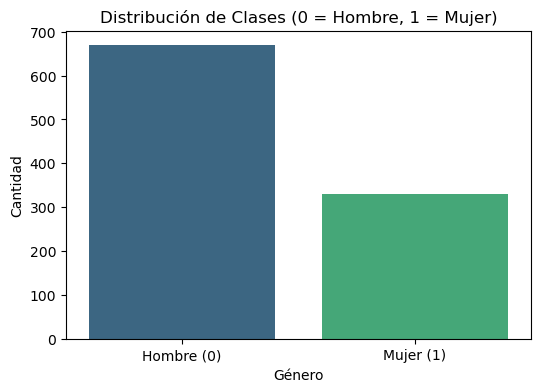


Distribución en TRAIN (desbalanceado):
genero
0    535
1    265
Name: count, dtype: int64

Distribución en TEST (desbalanceado):
genero
0    134
1     66
Name: count, dtype: int64

========== Original (Sin balancear) ==========
              precision    recall  f1-score   support

           0      0.760     0.948     0.844       134
           1      0.788     0.394     0.525        66

    accuracy                          0.765       200
   macro avg      0.774     0.671     0.685       200
weighted avg      0.770     0.765     0.739       200



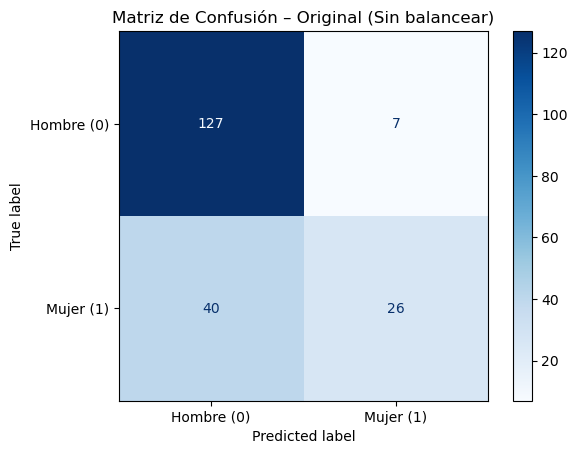


Distribución en TRAIN (SMOTE-simulado):
genero
0    535
1    535
Name: count, dtype: int64

========== SMOTE-simulado (Upsampling) ==========
              precision    recall  f1-score   support

           0      0.868     0.784     0.824       134
           1      0.633     0.758     0.690        66

    accuracy                          0.775       200
   macro avg      0.750     0.771     0.757       200
weighted avg      0.790     0.775     0.779       200



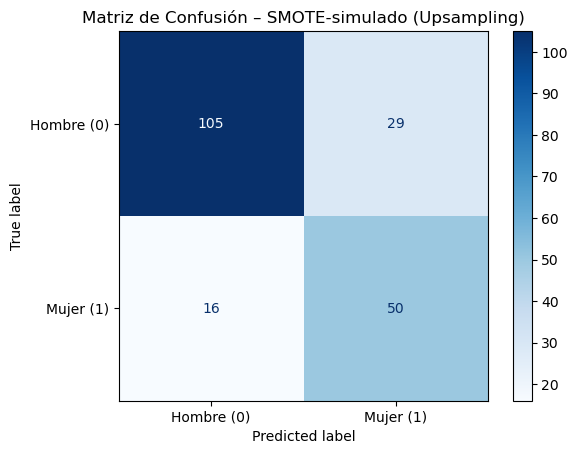


Distribución en TRAIN (RUS-simulado):
genero
0    265
1    265
Name: count, dtype: int64

========== RandomUnderSampler-simulado (Downsampling) ==========
              precision    recall  f1-score   support

           0      0.854     0.784     0.817       134
           1      0.623     0.727     0.671        66

    accuracy                          0.765       200
   macro avg      0.739     0.755     0.744       200
weighted avg      0.778     0.765     0.769       200



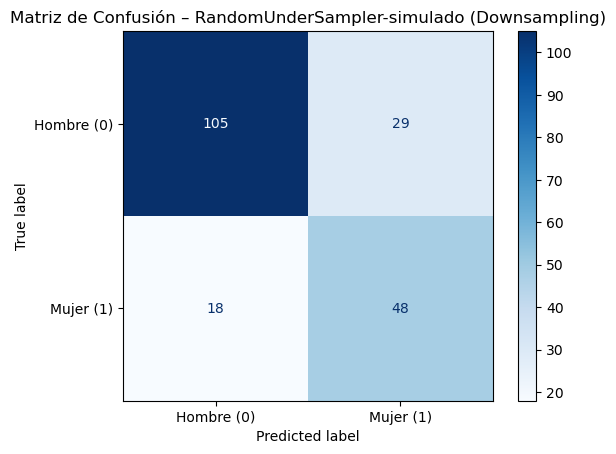

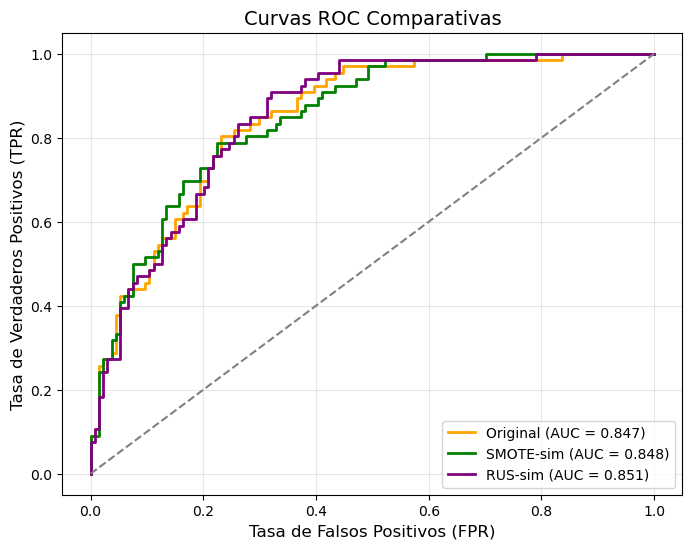


--- Resumen de distribuciones en TRAIN ---
Sin balancear: {0: 535, 1: 265}
SMOTE-simul: {0: 535, 1: 535}
RUS-simul: {0: 265, 1: 265}


In [33]:
# ---------------------------------------------
# EJEMPLO COMPLETO (sin imblearn) con CURVAS ROC y MATRICES
# ---------------------------------------------
# Genera los modelos sobre:
#  1) Dataset original (desbalanceado)
#  2) “SMOTE-simulado” (upsampling de clase minoritaria)
#  3) “RUS-simulado” (downsampling de clase mayoritaria)
#
# Y para cada caso:
#  • Imprime classification_report
#  • Dibuja la matriz de confusión
#  • Calcula y grafica la curva ROC
#
# ---------------------------------------------
# 0. Imports y generación del dataset desbalanceado
# ---------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)
from sklearn.utils import resample


# 1) Crear dataset desbalanceado (67% clase 0, 33% clase 1)
X, y = make_classification(
    n_samples     = 1000,
    n_features    = 10,
    n_informative = 8,
    n_redundant   = 2,
    n_classes     = 2,
    weights       = [0.67],    # 67% clase mayoritaria (hombre=0), 33% clase minoritaria (mujer=1)
    random_state  = 42
)

feature_names = [f"feature_{i}" for i in range(1, 11)]
df = pd.DataFrame(X, columns=feature_names)
df["genero"] = y  # 0 = Hombre, 1 = Mujer


# ---------------------------------------------
# 2) Visualizar distribución de clases
# ---------------------------------------------
plt.figure(figsize=(6, 4))
sns.countplot(x="genero", data=df, palette="viridis")
plt.title("Distribución de Clases (0 = Hombre, 1 = Mujer)", fontsize=12)
plt.xlabel("Género", fontsize=10)
plt.ylabel("Cantidad", fontsize=10)
plt.xticks([0, 1], ["Hombre (0)", "Mujer (1)"])
plt.show()


# ---------------------------------------------
# 3) Dividir en train y test (20% test, estratificado)
# ---------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    df[feature_names],
    df["genero"],
    test_size    = 0.20,
    random_state = 42,
    stratify     = df["genero"]
)

print("\nDistribución en TRAIN (desbalanceado):")
print(pd.Series(y_train).value_counts())
print("\nDistribución en TEST (desbalanceado):")
print(pd.Series(y_test).value_counts())


# ---------------------------------------------
# 4) Función auxiliar para entrenar y evaluar un modelo
# ---------------------------------------------
def entrenar_evaluar(name, X_tr, y_tr, X_te, y_te):
    """
    - name: texto descriptivo para títulos de salida
    - X_tr, y_tr: datos de entrenamiento
    - X_te, y_te: datos de prueba

    Entrena un LogisticRegression, imprime classification_report, dibuja la matriz de confusión
    y retorna las probabilidades (predict_proba) de la clase '1' para trazar ROC.
    """
    print(f"\n========== {name} ==========")
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_tr, y_tr)

    # Predicción y métricas
    y_pred = clf.predict(X_te)
    print(classification_report(y_te, y_pred, digits=3))

    # Matriz de confusión
    cm = confusion_matrix(y_te, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Hombre (0)", "Mujer (1)"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de Confusión – {name}")
    plt.show()

    # Obtener probabilidades de la clase '1'
    y_proba = clf.predict_proba(X_te)[:, 1]
    return y_proba


# ---------------------------------------------
# 5) Experimento A: Modelo con datos DESBALANCEADOS
# ---------------------------------------------
y_proba_unbalanced = entrenar_evaluar(
    name   = "Original (Sin balancear)",
    X_tr   = X_train,
    y_tr   = y_train,
    X_te   = X_test,
    y_te   = y_test
)


# ---------------------------------------------
# 6) Experimento B: “SMOTE-simulado” (upsampling de la clase minoritaria)
#     Usamos resample(), NO imblearn, para evitar el error de importación.
# ---------------------------------------------
# Antes de concatenar, resetear índices en ambos DataFrames para alinear filas correctamente:
train_X_reset = X_train.reset_index(drop=True)
train_y_reset = y_train.reset_index(drop=True)
train_data    = pd.concat([train_X_reset, train_y_reset], axis=1)

# Separar mayoritaria y minoritaria
majority = train_data[train_data["genero"] == 0]
minority = train_data[train_data["genero"] == 1]

# Upsampling de la clase minoritaria hasta igualar la cantidad de la mayoritaria
minority_upsampled = resample(
    minority,
    replace      = True,               # con reemplazo
    n_samples    = len(majority),      # igualar con majority
    random_state = 42
)

# Combinar majority + minority_upsampled
train_smote_sim = pd.concat([majority, minority_upsampled]).reset_index(drop=True)

# Separar en X_smote_sim / y_smote_sim
X_smote_sim = train_smote_sim[feature_names]
y_smote_sim = train_smote_sim["genero"]

print("\nDistribución en TRAIN (SMOTE-simulado):")
print(pd.Series(y_smote_sim).value_counts())

# Entrenar y evaluar el modelo SMOTE-simulado
y_proba_smote_sim = entrenar_evaluar(
    name   = "SMOTE-simulado (Upsampling)",
    X_tr   = X_smote_sim,
    y_tr   = y_smote_sim,
    X_te   = X_test,
    y_te   = y_test
)


# ---------------------------------------------
# 7) Experimento C: “RUS-simulado” (downsampling de la clase mayoritaria)
# ---------------------------------------------
# Reutilizamos majority y minority de arriba
# Downsampling de la clase mayoritaria hasta igualar la cantidad de la minoritaria
majority_downsampled = resample(
    majority,
    replace      = False,              # sin reemplazo (descarta instancias)
    n_samples    = len(minority),      # igualar con minority
    random_state = 42
)

# Combinar majority_downsampled + minority
train_rus_sim = pd.concat([majority_downsampled, minority]).reset_index(drop=True)

# Separar en X_rus_sim / y_rus_sim
X_rus_sim = train_rus_sim[feature_names]
y_rus_sim = train_rus_sim["genero"]

print("\nDistribución en TRAIN (RUS-simulado):")
print(pd.Series(y_rus_sim).value_counts())

# Entrenar y evaluar el modelo RUS-simulado
y_proba_rus_sim = entrenar_evaluar(
    name   = "RandomUnderSampler-simulado (Downsampling)",
    X_tr   = X_rus_sim,
    y_tr   = y_rus_sim,
    X_te   = X_test,
    y_te   = y_test
)


# ---------------------------------------------
# 8) Graficar las curvas ROC comparativas
# ---------------------------------------------
plt.figure(figsize=(8, 6))

# Calcular ROC para cada experimento
fpr_unb, tpr_unb, _ = roc_curve(y_test, y_proba_unbalanced)
fpr_sm,  tpr_sm,  _ = roc_curve(y_test, y_proba_smote_sim)
fpr_ru,  tpr_ru,  _ = roc_curve(y_test, y_proba_rus_sim)

auc_unb = auc(fpr_unb, tpr_unb)
auc_sm  = auc(fpr_sm,  tpr_sm)
auc_ru  = auc(fpr_ru,  tpr_ru)

plt.plot(fpr_unb, tpr_unb, label=f"Original (AUC = {auc_unb:.3f})",  color="orange", linewidth=2)
plt.plot(fpr_sm,  tpr_sm,  label=f"SMOTE-sim (AUC = {auc_sm:.3f})", color="green",  linewidth=2)
plt.plot(fpr_ru,  tpr_ru,  label=f"RUS-sim (AUC = {auc_ru:.3f})", color="purple",linewidth=2)

# Línea diagonal (clasificación aleatoria)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.title("Curvas ROC Comparativas", fontsize=14)
plt.xlabel("Tasa de Falsos Positivos (FPR)", fontsize=12)
plt.ylabel("Tasa de Verdaderos Positivos (TPR)", fontsize=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()


# ---------------------------------------------
# 9) Resumen final de distribuciones en TRAIN
# ---------------------------------------------
print("\n--- Resumen de distribuciones en TRAIN ---")
print("Sin balancear:",   pd.Series(y_train).value_counts().to_dict())
print("SMOTE-simul:",     pd.Series(y_smote_sim).value_counts().to_dict())
print("RUS-simul:",       pd.Series(y_rus_sim).value_counts().to_dict())

